In [5]:
print("Jupyter is working!")

Jupyter is working!


In [6]:
# 1. Load libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
# 2. Load the dataset

DATA_PATH = Path("student_performance.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "student_performance.csv not found. "
        "Place the CSV in your project folder."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 5000
Number of columns: 4


,study_hours,attendance,previous_marks,final_marks
0,6.3,53.1,75.5,70.3
1,3.8,79.8,74.8,69.5
2,6.9,86.0,39.2,56.1
3,5.7,50.0,27.6,33.2
4,1.2,42.6,46.3,42.7


In [9]:
# 3. Understand the dataset

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   study_hours     5000 non-null   float64
 1   attendance      5000 non-null   float64
 2   previous_marks  5000 non-null   float64
 3   final_marks     5000 non-null   float64
dtypes: float64(4)
memory usage: 156.4 KB

Statistical summary:


,study_hours,attendance,previous_marks,final_marks
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,4.217160,69.918160,60.112980,53.613460
std,2.164215,17.275939,20.045405,12.494725
min,0.500000,40.000000,25.000000,19.100000
25%,2.300000,54.900000,42.500000,44.800000
50%,4.200000,70.300000,60.350000,53.600000
75%,6.100000,84.525000,77.325000,62.600000
max,8.000000,100.000000,95.000000,90.700000



Column names:
['study_hours', 'attendance', 'previous_marks', 'final_marks']

Missing values:
study_hours       0
attendance        0
previous_marks    0
final_marks       0
dtype: int64

Duplicate rows: 0


In [10]:
# 4. Data preprocessing

required_columns = [
    "study_hours",
    "attendance",
    "previous_marks",
    "final_marks"
]

# Check whether all required columns exist
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Keep only the columns required for this project
df = df[required_columns].copy()

# Convert all columns to numeric values
for column in required_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Replace infinite values with NaN
df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing or invalid numeric values
rows_before = len(df)
df = df.dropna().copy()
rows_removed = rows_before - len(df)

# Validate expected ranges
valid_rows = (
    df["study_hours"].between(0, 24)
    & df["attendance"].between(0, 100)
    & df["previous_marks"].between(0, 100)
    & df["final_marks"].between(0, 100)
)

invalid_rows = int((~valid_rows).sum())

if invalid_rows > 0:
    print("Rows outside expected ranges:", invalid_rows)
    df = df.loc[valid_rows].copy()

df = df.reset_index(drop=True)

if len(df) < 10:
    raise ValueError("Too few valid records to train and test a model.")

print("Preprocessing completed!")
print("Rows removed due to missing/non-numeric values:", rows_removed)
print("Rows removed due to out-of-range values:", invalid_rows)
print("Final dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Preprocessing completed!
Rows removed due to missing/non-numeric values: 0
Rows removed due to out-of-range values: 0
Final dataset shape: (5000, 4)
Remaining missing values: 0


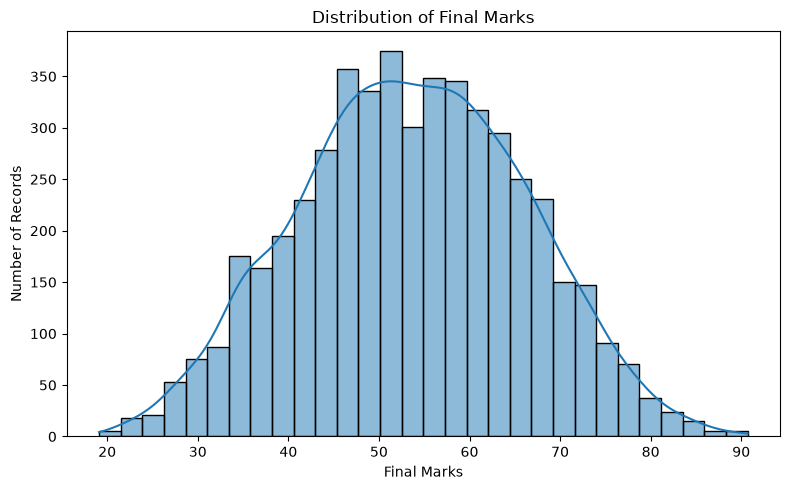

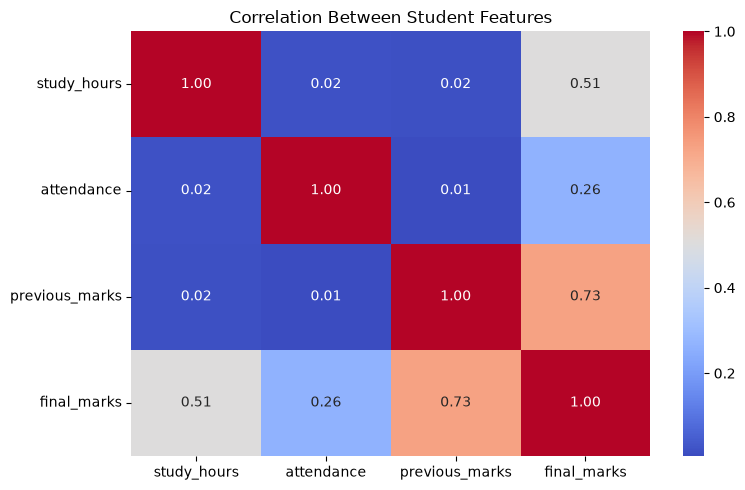

In [11]:
# 5. Explore relationships in the data

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="final_marks", bins=30, kde=True)
plt.title("Distribution of Final Marks")
plt.xlabel("Final Marks")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Student Features")
plt.tight_layout()
plt.show()

In [12]:
# 6. Separate input and output

FEATURES = [
    "study_hours",
    "attendance",
    "previous_marks"
]

TARGET = "final_marks"

X = df[FEATURES]
y = df[TARGET]

print("Input features (X):", X.shape)
print("Target variable (y):", y.shape)

print("\nInput sample:")
display(X.head())

print("\nTarget sample:")
display(y.head())

Input features (X): (5000, 3)
Target variable (y): (5000,)

Input sample:


,study_hours,attendance,previous_marks
0,6.3,53.1,75.5
1,3.8,79.8,74.8
2,6.9,86.0,39.2
3,5.7,50.0,27.6
4,1.2,42.6,46.3



Target sample:


0    70.3
1    69.5
2    56.1
3    33.2
4    42.7
Name: final_marks, dtype: float64

In [13]:
# 7. Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (4000, 3)
Testing input shape: (1000, 3)
Training target shape: (4000,)
Testing target shape: (1000,)


In [14]:
# 8. Define the models

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Models created successfully!")

Models created successfully!


In [15]:
# 9. Train the models

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} training completed!")

print("All models trained successfully.")

Linear Regression training completed!
Random Forest training completed!
All models trained successfully.


In [16]:
# 10. Evaluate both models

results = []
predictions = {}

for name, model in models.items():

    # Predict final marks for the testing data
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("Model comparison:")
display(results_df.round(4))

Model comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.1604,5.1690,0.8296
1,Random Forest,4.4580,5.5193,0.8058


In [17]:
# 11. Select the best model

best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Best model based on test RMSE:", best_model_name)
print("Test RMSE:", round(results_df.loc[0, "RMSE"], 4))
print("Test MAE:", round(results_df.loc[0, "MAE"], 4))
print("Test R2:", round(results_df.loc[0, "R2 Score"], 4))

Best model based on test RMSE: Linear Regression
Test RMSE: 5.169
Test MAE: 4.1604
Test R2: 0.8296


In [18]:
# 12. Compare actual and predicted values

best_predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Marks": y_test.to_numpy(),
    "Predicted Marks": best_predictions
})

comparison["Absolute Error"] = (
    comparison["Actual Marks"] - comparison["Predicted Marks"]
).abs()

display(comparison.head(10).round(2))

,Actual Marks,Predicted Marks,Absolute Error
0,60.6,62.18,1.58
1,31.3,32.46,1.16
2,68.0,59.14,8.86
3,60.4,59.99,0.41
4,51.3,55.92,4.62
5,46.2,43.61,2.59
6,55.7,47.07,8.63
7,45.8,50.56,4.76
8,69.2,69.44,0.24
9,73.0,68.03,4.97


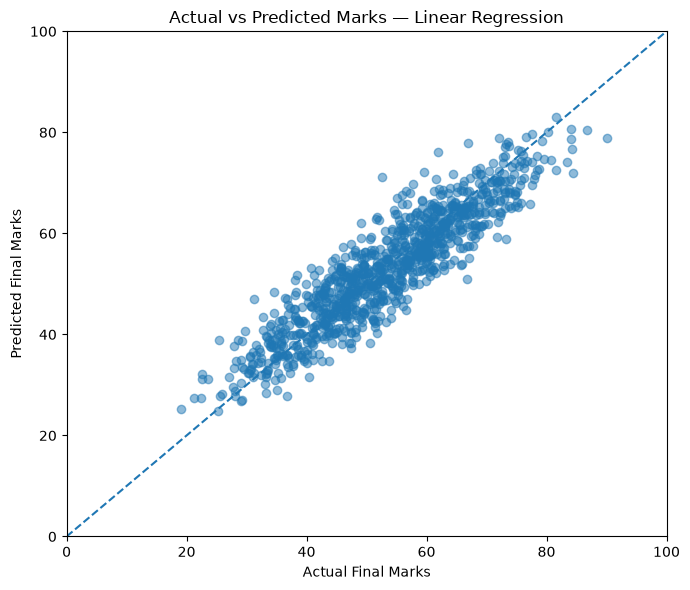

In [19]:
# 13. Plot actual versus predicted marks

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title(f"Actual vs Predicted Marks — {best_model_name}")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [20]:
# 14. Save the best model

MODEL_PATH = Path("student_model.pkl")

model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "features": FEATURES,
    "target": TARGET
}

joblib.dump(model_artifact, MODEL_PATH)

print("Model saved successfully!")
print("Saved location:", MODEL_PATH.resolve())

Model saved successfully!
Saved location: C:\Users\saipa\OneDrive\Desktop\StudentPerformanceProject\student_model.pkl


In [21]:
# 15. Load the saved model and predict a sample

loaded_artifact = joblib.load("student_model.pkl")
loaded_model = loaded_artifact["model"]

sample_student = pd.DataFrame([{
    "study_hours": 5.0,
    "attendance": 85.0,
    "previous_marks": 75.0
}])

sample_prediction = loaded_model.predict(sample_student)[0]

print("Selected model:", loaded_artifact["model_name"])
print("Predicted final marks:", round(float(sample_prediction), 2))

Selected model: Linear Regression
Predicted final marks: 65.17
